In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [4]:
data = pd.read_csv("loan.csv")

In [5]:
data.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


/tmp/ipykernel_3900/2670155480.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x = data["CoapplicantIncome"])


<Axes: ylabel='Density'>

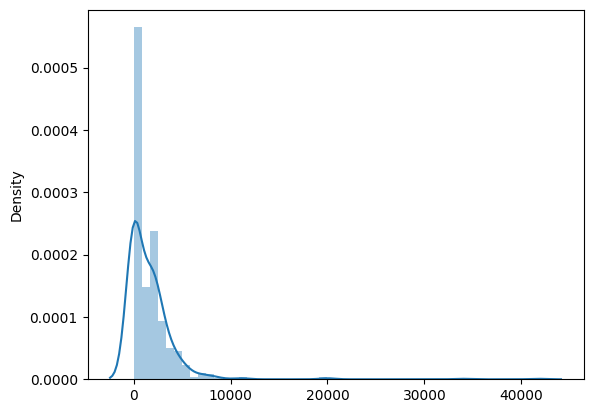

In [6]:
# to chck if the data is in normal distribution(bell shaped curve) or not(right skewed or left skewed)
sns.distplot(x = data["CoapplicantIncome"])

In [ ]:
# the graph is rightly skewed so its not following the normal distribution


In [8]:
# suing IQR method to remove outliers
q1 = data["CoapplicantIncome"].quantile(0.25)
q3 = data["CoapplicantIncome"].quantile(0.75)

In [10]:
# calculatin IQR
iqr = q3 - q1

In [12]:
min_range = q1 - (1.5 * iqr)
max_range = q2 + (1.5 * iqr)
min_range , max_range

(np.float64(-3445.875), np.float64(5743.125))

In [16]:
data = data[
    (data["CoapplicantIncome"] >= min_range)
    &
    (data["CoapplicantIncome"] <= max_range)
]

/tmp/ipykernel_3900/3617710387.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x = data["CoapplicantIncome"])


<Axes: ylabel='Density'>

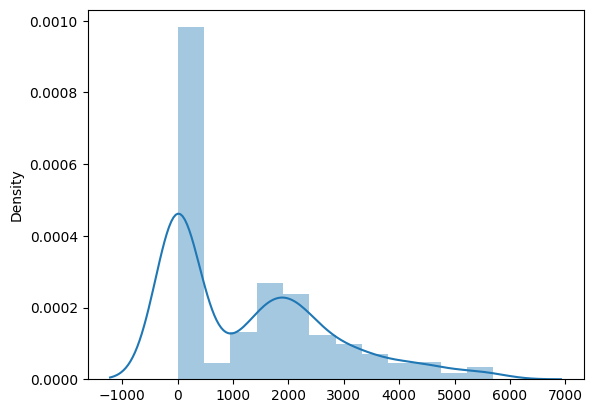

In [18]:
sns.distplot(x = data["CoapplicantIncome"])

In [23]:
# applying fucntion transformation
from sklearn.preprocessing import FunctionTransformer

In [25]:
# applyting log fucntion for function transformer

# log1p() means calculating the natural logarithm of (1 + x)
ft = FunctionTransformer(func = np.log1p)

## **FUNCTION TRANSFORMATION FOR LOG**

In [26]:
ft.fit(data[["CoapplicantIncome"]])

FunctionTransformer(func=<ufunc 'log1p'>)

In [27]:
ft.transform(data[["CoapplicantIncome"]])

,CoapplicantIncome
0,0.000000
1,7.319202
2,0.000000
3,7.765993
4,0.000000
...,...
609,0.000000
610,0.000000
611,5.484797
612,0.000000


In [28]:
data["CoapplicantIncome_ft"] = ft.transform(data[["CoapplicantIncome"]])

/tmp/ipykernel_3900/628766738.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome"])
/tmp/ipykernel_3900/628766738.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome_ft"])


Text(0.5, 1.0, 'After')

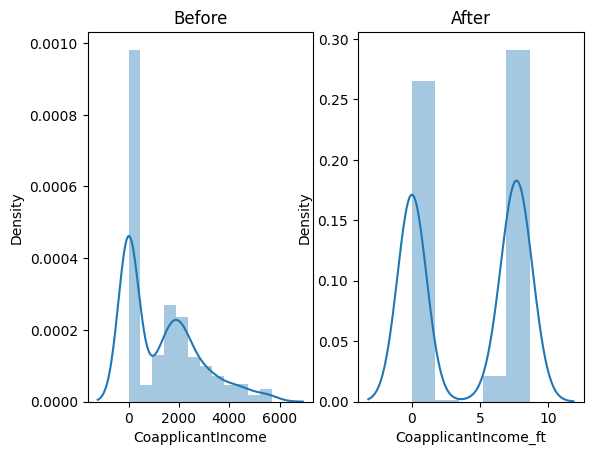

In [31]:
# drawing a subplot for compairng both before the data transformation and after the data transformation
plt.subplot(1 , 2 , 1)
sns.distplot(data["CoapplicantIncome"])
plt.title("Before")

plt.subplot(1 , 2 , 2)
sns.distplot(data["CoapplicantIncome_ft"])
plt.title("After")

FUNCTION TRANSFORMATION USING OUT OWN FUCNTION ( eg : square function )

In [39]:
ft1 = FunctionTransformer(func = lambda x : x ** 2)

In [33]:
ft1.fit(data[["CoapplicantIncome"]])

FunctionTransformer(func=<function <lambda> at 0x7f32c12f6c00>)

In [34]:
ft1.transform(data[["CoapplicantIncome"]])

,CoapplicantIncome
0,0.0
1,2274064.0
2,0.0
3,5560164.0
4,0.0
...,...
609,0.0
610,0.0
611,57600.0
612,0.0


In [36]:
data["CoapplicantIncome_ft_2"] = ft1.transform(data[["CoapplicantIncome"]])

/tmp/ipykernel_3900/1513572201.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome"])
/tmp/ipykernel_3900/1513572201.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome_ft_2"])


Text(0.5, 1.0, 'After')

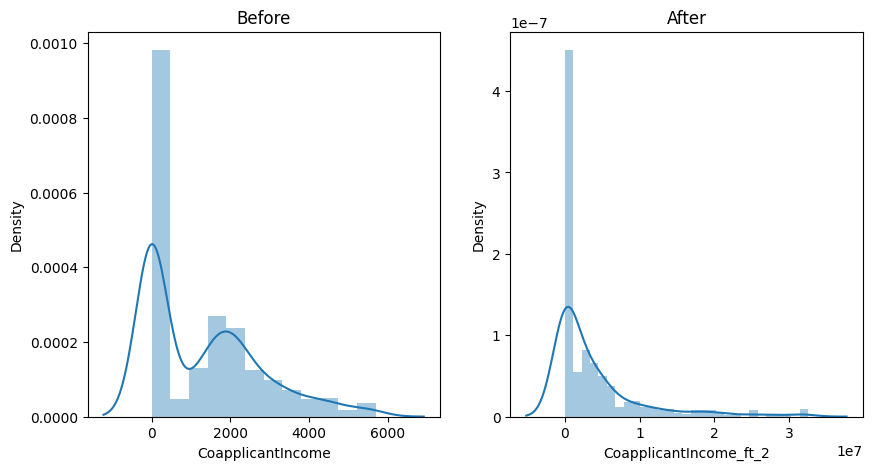

In [38]:
plt.figure( figsize = (10 , 5) )

plt.subplot(1 , 2 , 1)
sns.distplot(data["CoapplicantIncome"])
plt.title("Before")

plt.subplot(1 , 2 , 2)
sns.distplot(data["CoapplicantIncome_ft_2"])
plt.title("After")

FUNCTION TRANSFORMATION USING SQUARE FUCNTION(sqrt)

In [42]:
ft3 = FunctionTransformer(func=np.sqrt)

In [43]:
ft3.fit(data[["CoapplicantIncome"]])

FunctionTransformer(func=<ufunc 'sqrt'>)

In [44]:
ft3.transform(data[["CoapplicantIncome"]])

,CoapplicantIncome
0,0.000000
1,38.832976
2,0.000000
3,48.559242
4,0.000000
...,...
609,0.000000
610,0.000000
611,15.491933
612,0.000000


In [45]:
data["CoapplicantIncome_ft_3"] = ft3.transform( data [ [ "CoapplicantIncome" ] ] )

/tmp/ipykernel_3900/90893037.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome"])
/tmp/ipykernel_3900/90893037.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome_ft_3"])


Text(0.5, 1.0, 'After')

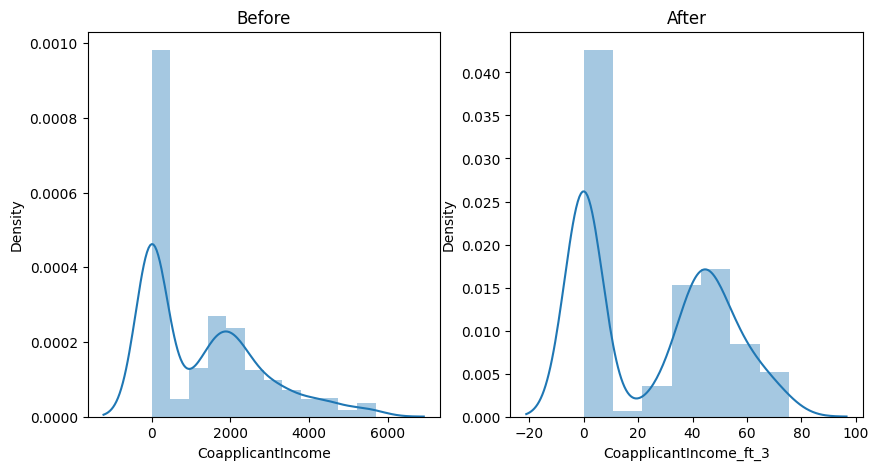

In [46]:
# plotting graphs
plt.figure( figsize = (10 , 5) )

plt.subplot(1 , 2 , 1)
sns.distplot(data["CoapplicantIncome"])
plt.title("Before")

plt.subplot(1 , 2 , 2)
sns.distplot(data["CoapplicantIncome_ft_3"])
plt.title("After")

FUNCTION TRANSFORMATION USING RECIPROCAL FUNCTION

In [49]:
ft4 = FunctionTransformer(func=np.reciprocal)

ft4.fit(data[["CoapplicantIncome"]])

data["CoapplicantIncome_ft_4"] = ft.transform(
    data[["CoapplicantIncome"]]
)

/tmp/ipykernel_3900/2236702672.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome"])
/tmp/ipykernel_3900/2236702672.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome_ft_4"])


Text(0.5, 1.0, 'After')

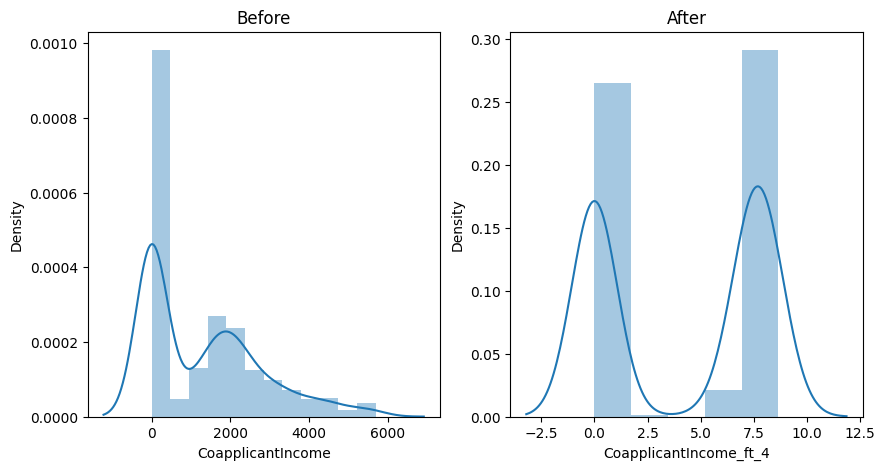

In [50]:
# plotting graphs
plt.figure( figsize = (10 , 5) )

plt.subplot(1 , 2 , 1)
sns.distplot(data["CoapplicantIncome"])
plt.title("Before")

plt.subplot(1 , 2 , 2)
sns.distplot(data["CoapplicantIncome_ft_4"])
plt.title("After")

FUNCTION TRANFORMATION USING POWER FUNCTION

In [51]:
ft5 = FunctionTransformer(func=np.reciprocal)

ft5.fit(data[["CoapplicantIncome"]])

data["CoapplicantIncome_ft_5"] = ft.transform(
    data[["CoapplicantIncome"]]
)

/tmp/ipykernel_3900/1554044291.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome"])
/tmp/ipykernel_3900/1554044291.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["CoapplicantIncome_ft_5"])


Text(0.5, 1.0, 'After')

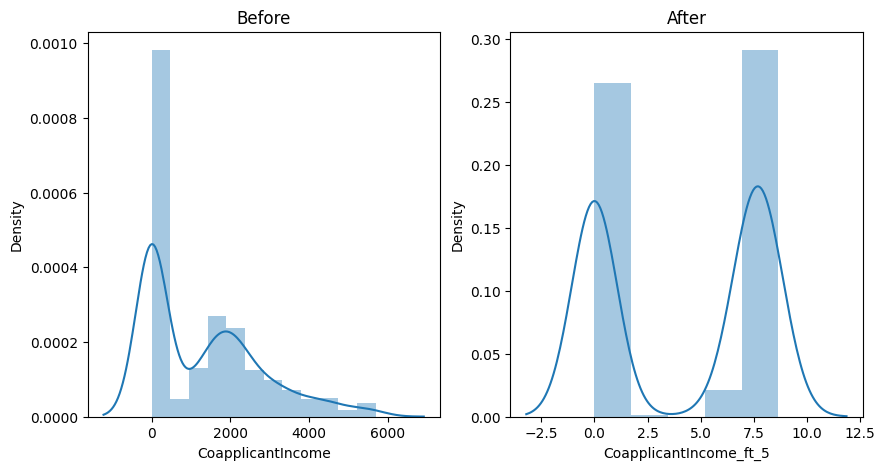

In [52]:
# plotting graphs
plt.figure( figsize = (10 , 5) )

plt.subplot(1 , 2 , 1)
sns.distplot(data["CoapplicantIncome"])
plt.title("Before")

plt.subplot(1 , 2 , 2)
sns.distplot(data["CoapplicantIncome_ft_5"])
plt.title("After")